# Model training

Train and compare classifiers using the processed data generated by `02_preprocessing.ipynb`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/alaric/Desktop/studies/projects/ML/mental-health-risk-prediction


In [2]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train_processed.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_processed.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

print(f"Training shape: {X_train.shape}")
print(f"Testing shape: {X_test.shape}")
print(f"Classes: {sorted(y_train.unique())}")

Training shape: (1600, 23)
Testing shape: (400, 23)
Classes: [np.int64(0), np.int64(1), np.int64(2)]


In [3]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

In [4]:
cv_results = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision_macro"].mean(),
        "Recall": scores["test_recall_macro"].mean(),
        "F1-score": scores["test_f1_macro"].mean(),
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7500,0.7494,0.7494,0.7486
1,Random Forest,0.6794,0.6715,0.6783,0.6725
2,XGBoost,0.6950,0.6960,0.6942,0.6942


In [5]:
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.
XGBoost trained successfully.


In [9]:
test_results = []
confusion_matrices = {}
class_labels = sorted(y_test.unique())
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    confusion_matrices[name] = confusion_matrix(y_test, y_pred, labels=class_labels)
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })
    print(f"\n============================================================================ {name} ============================================================================")
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(pd.DataFrame(
        confusion_matrices[name],
        index=[f"Actual {label}" for label in class_labels],
        columns=[f"Predicted {label}" for label in class_labels],
    ))
    print(classification_report(y_test, y_pred, zero_division=0))

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))


============================================================================ Logistic Regression ============================================================================
Confusion matrix (rows = actual, columns = predicted):
          Predicted 0  Predicted 1  Predicted 2
Actual 0          112            0           24
Actual 1            1          107           24
Actual 2           25           24           83
              precision    recall  f1-score   support

           0       0.81      0.82      0.82       136
           1       0.82      0.81      0.81       132
           2       0.63      0.63      0.63       132

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.76      0.75       400


============================================================================ Random Forest ============================================================================
Confusion matrix (rows = act

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7550,0.7540,0.7543,0.7541
1,Random Forest,0.7075,0.7059,0.7068,0.7064
2,XGBoost,0.7325,0.7303,0.7320,0.7310


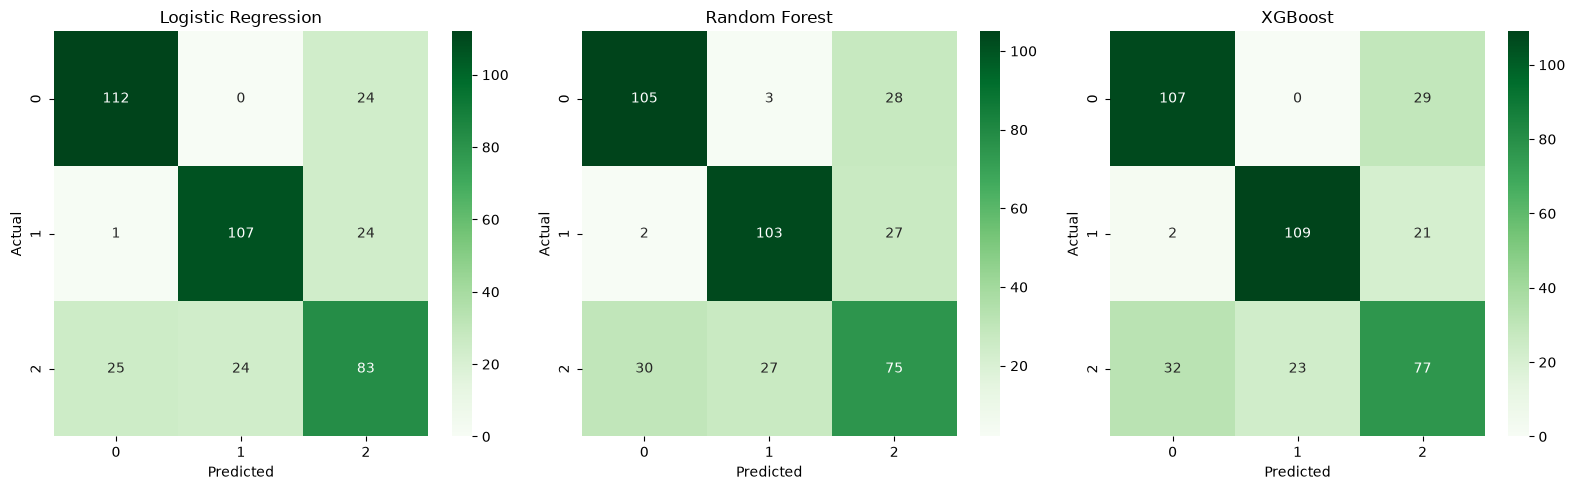

In [7]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(16, 5))
for ax, name in zip(axes, trained_models):
    sns.heatmap(
        confusion_matrices[name],
        annot=True,
        fmt="d",
        cmap="Greens",
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [8]:
for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, MODELS_DIR / filename)
    matrix_filename = name.lower().replace(" ", "_") + "_confusion_matrix.csv"
    pd.DataFrame(
        confusion_matrices[name],
        index=[f"Actual {label}" for label in class_labels],
        columns=[f"Predicted {label}" for label in class_labels],
    ).to_csv(RESULTS_DIR / matrix_filename)

cv_results_df.to_csv(RESULTS_DIR / "cross_validation_results.csv", index=False)
test_results_df.to_csv(RESULTS_DIR / "model_comparison_results.csv", index=False)

print(f"Saved models to: {MODELS_DIR}")
print(f"Saved results to: {RESULTS_DIR}")

Saved models to: /home/alaric/Desktop/studies/projects/ML/mental-health-risk-prediction/models
Saved results to: /home/alaric/Desktop/studies/projects/ML/mental-health-risk-prediction/results
